# Kenyan Food Market Prices, 2018–2026
### Drought shocks, seasonality and regional price gaps across 12 markets

**Business questions**
1. How hard did the 2021–23 drought hit staple food prices, and which markets were hit hardest?
2. When in the year are prices seasonally high or low?
3. How much more do households in arid and semi-arid (ASAL) counties pay?
4. Which commodities are the most volatile, and how much of recent price movement is a currency effect?
5. Where are maize prices likely to go over the next 12 months?

**Data.** A monthly market-price panel in the schema of the WFP *Kenya – Food Prices* dataset on HDX
(retail prices for 6 commodities in 12 markets, plus wholesale maize in 5 markets).
⚠️ The data in this repo are **simulated** (see `src/generate_data.py`). The pipeline runs unchanged on the real HDX file.

**Pipeline.** `generate_data.py` → `clean.py` → `load_db.py` (SQLite star schema + 10 SQL queries) → this notebook.

In [1]:
import sqlite3
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import numpy as np
import pandas as pd
from statsmodels.tsa.statespace.sarimax import SARIMAX
import warnings
warnings.filterwarnings("ignore")

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DB = ROOT / "data" / "kenya_food_prices.db"
FIG = ROOT / "reports" / "figures"
FIG.mkdir(parents=True, exist_ok=True)
con = sqlite3.connect(DB)

def sql(query: str) -> pd.DataFrame:
    return pd.read_sql_query(query, con)

def sql_file(name: str) -> pd.DataFrame:
    """Run a named query from sql/analysis_queries.sql"""
    import re
    text = (ROOT / "sql" / "analysis_queries.sql").read_text()
    parts = re.split(r"^-- name:\s*(\w+)\s*$", text, flags=re.M)[1:]
    return sql(dict(zip(parts[::2], parts[1::2]))[name])

# ---- chart style: one quiet house style for every figure ----
SURFACE, INK, INK2, MUTED, GRID, AXIS = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
BLUE, ORANGE, AQUA, YELLOW, MAGENTA, GREEN = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300"
GRAY = "#b9b8b0"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "font.family": "DejaVu Sans", "font.size": 10, "text.color": INK,
    "axes.edgecolor": AXIS, "axes.labelcolor": INK2, "axes.titlesize": 11, "axes.titleweight": "bold",
    "axes.titlelocation": "left", "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "xtick.color": MUTED, "ytick.color": MUTED, "xtick.labelcolor": INK2, "ytick.labelcolor": INK2,
    "lines.linewidth": 2, "legend.frameon": False, "figure.dpi": 110, "savefig.dpi": 150,
    "savefig.bbox": "tight",
})
DROUGHT = (pd.Timestamp("2021-10-01"), pd.Timestamp("2023-06-01"))
def shade_drought(ax, label=False):
    ax.axvspan(*DROUGHT, color="#f0efec", zorder=0, lw=0)
    if label:
        ax.text(DROUGHT[0] + pd.Timedelta(days=20), 0.03, "2021–23 drought", transform=ax.get_xaxis_transform(),
                va="bottom", fontsize=8, color=INK2)

## 1. Data overview and quality
The database is a small star schema: `fact_price` joined to `dim_market`, `dim_commodity` and `dim_fx`, with a `v_price` view for analysis.

In [2]:
print((ROOT / "reports" / "cleaning_log.md").read_text())
sql("""
SELECT price_type, COUNT(*) AS rows, COUNT(DISTINCT market) AS markets,
       COUNT(DISTINCT commodity) AS commodities, MIN(month) AS first_month, MAX(month) AS last_month
FROM v_price GROUP BY price_type
""")

# Cleaning log

1. Loaded `wfp_food_prices_ken_synthetic.csv`: 7,811 rows, 14 columns
2. Standardised labels: commodities 12 -> 6, markets 24 -> 12
3. Removed 60 exact duplicate rows
4. Collapsed 0 conflicting duplicates (median kept)
5. Removed 6 rows with zero/negative/missing price
6. Converted 511 bulk-unit prices (e.g. 90 KG bag) to per-KG
7. Outlier check (|robust z| > 6 and >2.5x off rolling median): repaired 14 decimal slips (/10), dropped 0 others
8. Final: 7,745 rows; 12 markets, 6 commodities, Jan 2018 - Sep 2026; panel coverage 95.8%



,price_type,rows,markets,commodities,first_month,last_month
0,Retail,7234,12,6,2018-01-01,2026-09-01
1,Wholesale,511,5,1,2018-01-01,2026-09-01


In [3]:
coverage = sql_file("q01_data_coverage")
coverage

,market,county,zone,observations,months_reported,months_in_period,coverage_pct
0,Garissa,Garissa,ASAL,577,105,105,91.6
1,Lodwar,Turkana,ASAL,580,105,105,92.1
2,Marsabit,Marsabit,ASAL,580,105,105,92.1
3,Mandera,Mandera,ASAL,581,102,105,92.2
4,Kakamega,Kakamega,High-potential,609,105,105,96.7
5,Nairobi,Nairobi,High-potential,713,105,105,97.0
6,Kisumu,Kisumu,High-potential,716,105,105,97.4
7,Eldoret,Uasin Gishu,High-potential,717,105,105,97.6
8,Karatina,Nyeri,High-potential,615,105,105,97.6
9,Kitui,Kitui,ASAL,616,105,105,97.8


Coverage is above 91% in every market. The four remote northern markets (Garissa, Lodwar, Marsabit, Mandera) have the most gaps, and Mandera has a 3-month hole in 2021. Gaps are left as missing rather than imputed, so averages are computed over reported months only.

## 2. Price trends: the 2021–23 drought dominates the decade

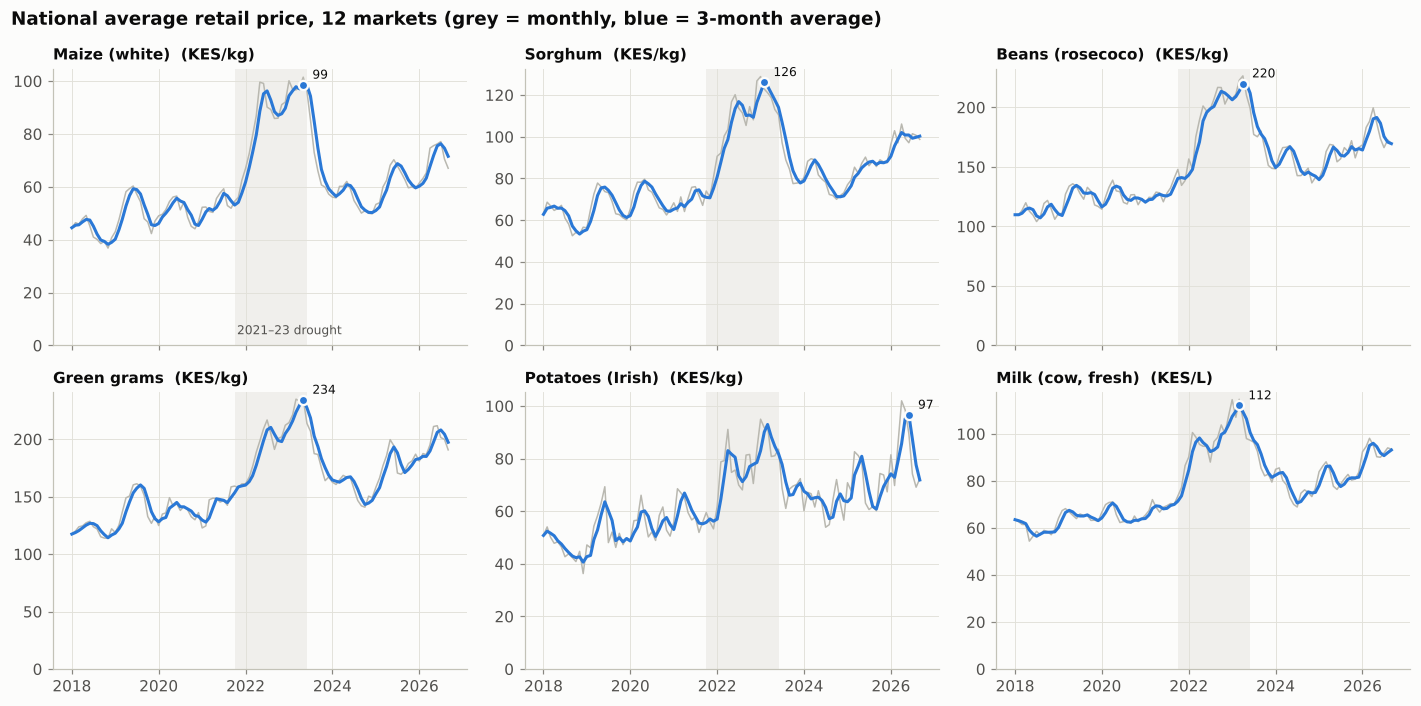

In [4]:
national = sql_file("q02_national_monthly_index")
national["month"] = pd.to_datetime(national["month"])
order = ["Maize (white)", "Sorghum", "Beans (rosecoco)", "Green grams", "Potatoes (Irish)", "Milk (cow, fresh)"]
units = {c: "KES/L" if "Milk" in c else "KES/kg" for c in order}

fig, axes = plt.subplots(2, 3, figsize=(13, 6.5), sharex=True)
for ax, c in zip(axes.flat, order):
    d = national[national["commodity"] == c]
    shade_drought(ax, label=(c == order[0]))
    ax.plot(d["month"], d["avg_price_kes"], color=GRAY, lw=1)
    ax.plot(d["month"], d["rolling_3m_kes"], color=BLUE)
    peak = d.loc[d["rolling_3m_kes"].idxmax()]
    ax.plot(peak["month"], peak["rolling_3m_kes"], "o", color=BLUE, ms=6, mec=SURFACE, mew=1.5)
    ax.annotate(f"{peak['rolling_3m_kes']:.0f}", (peak["month"], peak["rolling_3m_kes"]),
                xytext=(6, 4), textcoords="offset points", fontsize=8, color=INK)
    ax.set_title(f"{c}  ({units[c]})", fontsize=10)
    ax.set_ylim(bottom=0)
    ax.xaxis.set_major_locator(mdates.YearLocator(2))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
fig.suptitle("National average retail price, 12 markets (grey = monthly, blue = 3-month average)",
             x=0.01, ha="left", fontsize=12, fontweight="bold")
fig.tight_layout()
fig.savefig(FIG / "01_national_price_trends.png")
plt.show()

In [5]:
# Peak year-on-year inflation by commodity
yoy = (national.dropna(subset=["yoy_pct"]).sort_values("yoy_pct", ascending=False)
       .groupby("commodity").head(1)[["commodity", "month", "avg_price_kes", "yoy_pct"]])
yoy["month"] = yoy["month"].dt.strftime("%b %Y")
yoy.rename(columns={"month": "peak_yoy_month"}).reset_index(drop=True)

,commodity,peak_yoy_month,avg_price_kes,yoy_pct
0,Maize (white),May 2022,99.60,79.2
1,Sorghum,May 2022,116.69,65.8
2,Beans (rosecoco),Jun 2022,196.88,63.1
3,Potatoes (Irish),Dec 2022,83.50,56.6
4,"Milk (cow, fresh)",Feb 2022,100.58,49.2
5,Green grams,Jul 2022,216.75,47.8


## 3. Drought impact by market: the arid north paid the most

In [6]:
drought = sql_file("q03_drought_impact_maize")
drought

,market,zone,baseline_2019_20_kes,drought_peak_kes,peak_month,increase_pct,rank_hardest_hit
0,Mandera,ASAL,64.37,155.56,2023-01-01,141.7,1
1,Lodwar,ASAL,63.47,147.23,2023-05-01,132.0,2
2,Marsabit,ASAL,61.31,136.17,2023-01-01,122.1,3
3,Kitui,ASAL,52.39,115.25,2023-01-01,120.0,4
4,Garissa,ASAL,58.36,121.80,2022-05-01,108.7,5
5,Mombasa,High-potential,50.71,102.94,2023-04-01,103.0,6
6,Kisumu,High-potential,47.29,89.60,2023-05-01,89.5,7
7,Nairobi,High-potential,46.70,86.67,2023-05-01,85.6,8
8,Kakamega,High-potential,42.16,77.83,2023-01-01,84.6,9
9,Karatina,High-potential,44.79,79.93,2023-04-01,78.4,10


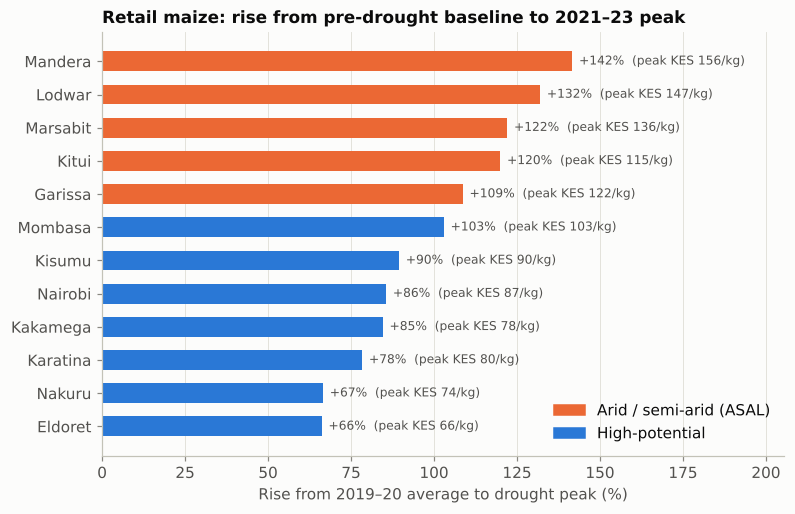

Average peak rise: ASAL 125% vs high-potential 82%


In [7]:
d = drought.sort_values("increase_pct")
colors = [ORANGE if z == "ASAL" else BLUE for z in d["zone"]]
fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(d["market"], d["increase_pct"], color=colors, height=0.6)
for y, (v, p) in enumerate(zip(d["increase_pct"], d["drought_peak_kes"])):
    ax.text(v + 2, y, f"+{v:.0f}%  (peak KES {p:.0f}/kg)", va="center", fontsize=8, color=INK2)
ax.set_xlabel("Rise from 2019–20 average to drought peak (%)")
ax.grid(axis="y", visible=False)
ax.set_xlim(0, d["increase_pct"].max() * 1.45)
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=ORANGE, label="Arid / semi-arid (ASAL)"), Patch(color=BLUE, label="High-potential")],
          loc="lower right")
ax.set_title("Retail maize: rise from pre-drought baseline to 2021–23 peak")
fig.savefig(FIG / "02_drought_impact_maize.png")
plt.show()

asal_avg = drought.groupby("zone")["increase_pct"].mean()
print(f"Average peak rise: ASAL {asal_avg['ASAL']:.0f}% vs high-potential {asal_avg['High-potential']:.0f}%")

## 4. Seasonality: when to buy and when to sell

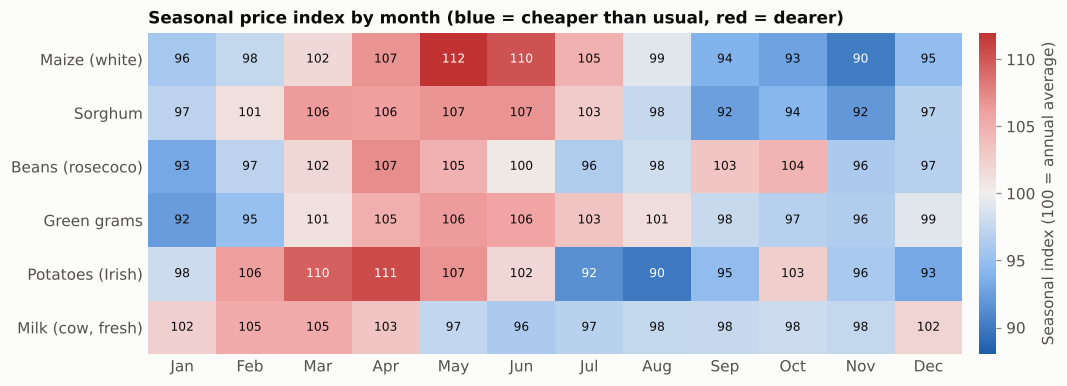

,cheapest_month,low,dearest_month,high,peak_to_trough_pct
commodity,,,,,
Maize (white),Nov,90.2,May,112.3,24.5
Sorghum,Nov,92.1,Jun,106.8,16.0
Beans (rosecoco),Jan,93.1,Apr,107.1,15.0
Green grams,Jan,92.4,May,106.3,15.0
Potatoes (Irish),Aug,89.9,Apr,110.6,23.0
"Milk (cow, fresh)",Jun,96.2,Mar,105.4,9.6


In [8]:
season = sql_file("q04_seasonal_index").pivot(index="commodity", columns="month_num", values="seasonal_index").loc[order]
season.columns = ["Jan","Feb","Mar","Apr","May","Jun","Jul","Aug","Sep","Oct","Nov","Dec"]

from matplotlib.colors import LinearSegmentedColormap, TwoSlopeNorm
div = LinearSegmentedColormap.from_list("div", ["#1c5cab", "#86b6ef", "#f0efec", "#f0a3a2", "#c03332"])
fig, ax = plt.subplots(figsize=(10, 3.8))
im = ax.imshow(season.values, cmap=div, norm=TwoSlopeNorm(vcenter=100, vmin=88, vmax=112), aspect="auto")
ax.set_xticks(range(12), season.columns); ax.set_yticks(range(len(order)), season.index)
ax.grid(False)
for i in range(season.shape[0]):
    for j in range(12):
        v = season.values[i, j]
        ax.text(j, i, f"{v:.0f}", ha="center", va="center", fontsize=8,
                color="#ffffff" if abs(v - 100) > 8 else INK)
ax.tick_params(length=0)
for s in ax.spines.values(): s.set_visible(False)
cb = fig.colorbar(im, ax=ax, fraction=0.025, pad=0.02); cb.outline.set_visible(False)
cb.set_label("Seasonal index (100 = annual average)", color=INK2)
ax.set_title("Seasonal price index by month (blue = cheaper than usual, red = dearer)")
fig.savefig(FIG / "03_seasonality_heatmap.png")
plt.show()

summary = pd.DataFrame({"cheapest_month": season.idxmin(axis=1), "low": season.min(axis=1),
                        "dearest_month": season.idxmax(axis=1), "high": season.max(axis=1)})
summary["peak_to_trough_pct"] = (100 * (summary["high"] / summary["low"] - 1)).round(1)
summary

**Reading the pattern.** Maize and sorghum are cheapest just after the main long-rains harvest (Oct–Nov) and dearest
in the lean season before it (Apr–Jun). Milk is dearest in the January–March
dry season, when pasture is scarce. Maize and potatoes have the widest seasonal swing (about 25% from trough to peak) and milk the narrowest (about 10%). For a trader or a school-feeding programme, buying maize in Oct–Nov rather than May–Jun saves the
peak-to-trough gap shown above on average.

## 5. The ASAL premium: remote markets pay 25–40% more in normal years

In [9]:
prem = sql_file("q05_asal_premium")
prem.pivot(index="year", columns="commodity", values="asal_premium_pct")[order]

commodity,Maize (white),Sorghum,Beans (rosecoco),Green grams,Potatoes (Irish),"Milk (cow, fresh)"
year,,,,,,
2018,28.1,30.2,28.9,25.8,38.9,32.1
2019,37.4,36.8,32.6,29.9,37.4,36.0
2020,28.4,33.5,32.7,27.1,33.3,30.1
2021,32.5,30.8,33.3,29.1,38.2,28.2
2022,63.5,55.6,54.9,48.5,58.8,48.2
2023,56.6,49.0,50.1,47.6,50.0,44.2
2024,23.5,27.8,25.8,24.6,44.0,24.7
2025,28.0,30.5,26.9,26.9,41.5,25.7
2026,37.2,32.1,32.3,29.5,48.5,33.9


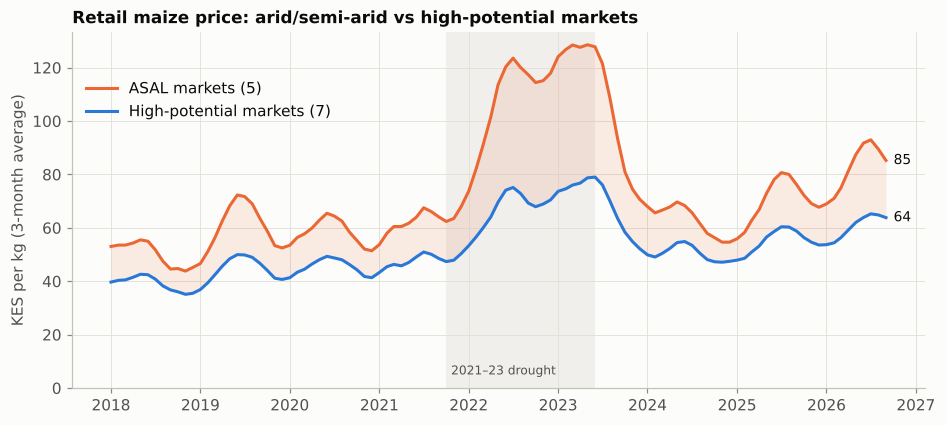

In [10]:
zone_ts = sql("""
SELECT month, zone, AVG(price_kes) AS price
FROM v_price WHERE commodity = 'Maize (white)' AND price_type = 'Retail'
GROUP BY month, zone ORDER BY month
""")
zone_ts["month"] = pd.to_datetime(zone_ts["month"])
z = zone_ts.pivot(index="month", columns="zone", values="price").rolling(3, min_periods=1).mean()
fig, ax = plt.subplots(figsize=(10, 4.2))
shade_drought(ax, label=True)
ax.fill_between(z.index, z["High-potential"], z["ASAL"], color=ORANGE, alpha=0.12, lw=0)
ax.plot(z.index, z["ASAL"], color=ORANGE, label="ASAL markets (5)")
ax.plot(z.index, z["High-potential"], color=BLUE, label="High-potential markets (7)")
for col, colr in [("ASAL", ORANGE), ("High-potential", BLUE)]:
    ax.annotate(f"{z[col].iloc[-1]:.0f}", (z.index[-1], z[col].iloc[-1]), xytext=(5, 0),
                textcoords="offset points", va="center", fontsize=9, color=INK)
ax.set_ylabel("KES per kg (3-month average)"); ax.set_ylim(bottom=0)
ax.legend(loc="upper left", bbox_to_anchor=(0, 0.9))
ax.set_title("Retail maize price: arid/semi-arid vs high-potential markets")
fig.savefig(FIG / "04_asal_vs_highpotential_maize.png")
plt.show()

The premium is not fixed: it roughly doubles in a drought year because ASAL markets depend on grain trucked in from the Rift Valley and local supply collapses first. Price gaps are a measure of market access as much as of scarcity.

In [11]:
integ = sql_file("q10_market_integration")
integ

,market,zone,n_months,corr_with_nairobi,avg_gap_vs_nairobi_pct
0,Eldoret,High-potential,96,0.964,-16.0
1,Kitui,ASAL,95,0.959,16.2
2,Kisumu,High-potential,97,0.958,0.5
3,Karatina,High-potential,96,0.957,-5.8
4,Marsabit,ASAL,88,0.957,37.1
5,Nakuru,High-potential,99,0.957,-8.8
6,Mandera,ASAL,91,0.955,46.4
7,Mombasa,High-potential,100,0.955,9.1
8,Kakamega,High-potential,96,0.951,-8.5
9,Garissa,ASAL,89,0.941,25.1


All markets track Nairobi closely (correlation > 0.93), so price signals do travel nationally. The difference is in **level**, not direction: Mandera and Lodwar sit about 45% above Nairobi on average.

## 6. Volatility and the currency effect

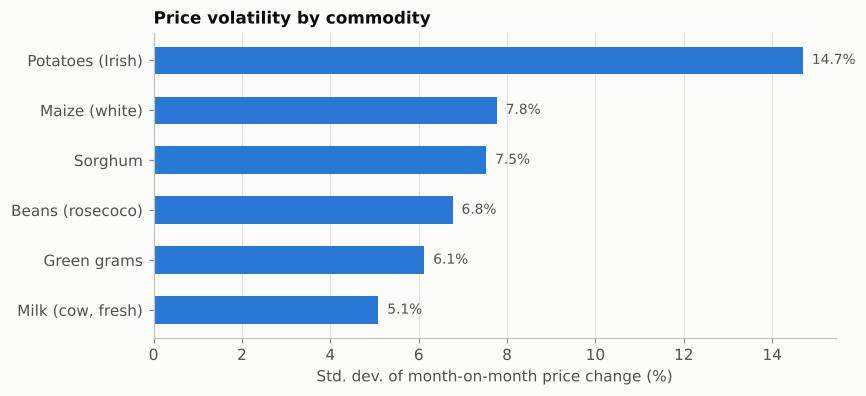

,commodity,n_changes,mean_mom_pct,volatility_pct,largest_rise_pct,largest_fall_pct
0,Potatoes (Irish),1196,0.36,14.70,46.4,-51.7
1,Maize (white),1181,0.44,7.77,28.7,-42.2
2,Sorghum,1199,0.45,7.53,32.6,-29.4
3,Beans (rosecoco),1198,0.45,6.77,23.7,-23.7
4,Green grams,1195,0.48,6.13,17.9,-23.9
5,"Milk (cow, fresh)",1193,0.37,5.09,20.8,-15.0


In [12]:
vol = sql_file("q06_volatility")
fig, ax = plt.subplots(figsize=(8, 3.6))
v = vol.sort_values("volatility_pct")
ax.barh(v["commodity"], v["volatility_pct"], color=BLUE, height=0.55)
for y, val in enumerate(v["volatility_pct"]):
    ax.text(val + 0.2, y, f"{val:.1f}%", va="center", fontsize=9, color=INK2)
ax.grid(axis="y", visible=False)
ax.set_xlabel("Std. dev. of month-on-month price change (%)")
ax.set_title("Price volatility by commodity")
fig.savefig(FIG / "05_volatility.png")
plt.show()
vol

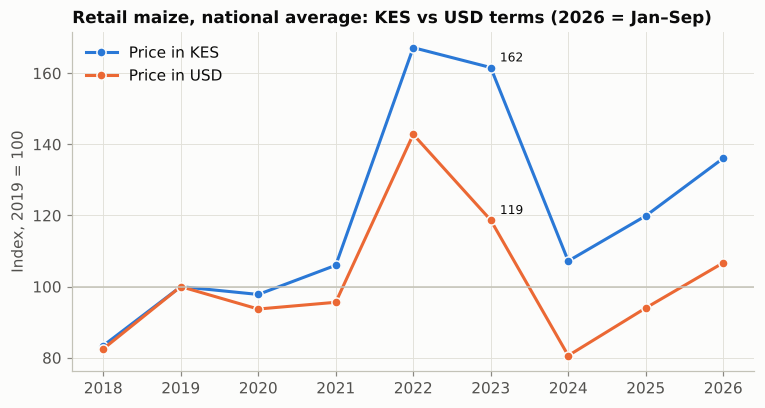

,year,maize_kes,maize_usd,kes_per_usd,kes_index_2019,usd_index_2019
0,2018,43.00,0.420,102.3,83.4,82.5
1,2019,51.58,0.509,101.3,100.0,100.0
2,2020,50.44,0.477,105.9,97.8,93.7
3,2021,54.70,0.487,111.6,106.0,95.6
4,2022,86.22,0.727,117.9,167.2,142.8
5,2023,83.37,0.604,140.3,161.6,118.7
6,2024,55.27,0.411,135.0,107.2,80.6
7,2025,61.87,0.479,129.3,119.9,94.0
8,2026,70.20,0.543,129.2,136.1,106.7


In [13]:
fx = sql_file("q09_price_in_usd_vs_kes")
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(fx["year"], fx["kes_index_2019"], color=BLUE, marker="o", ms=6, mec=SURFACE, label="Price in KES")
ax.plot(fx["year"], fx["usd_index_2019"], color=ORANGE, marker="o", ms=6, mec=SURFACE, label="Price in USD")
ax.axhline(100, color=AXIS, lw=1)
for col in ["kes_index_2019", "usd_index_2019"]:
    r = fx.loc[fx["year"] == 2023].iloc[0]
    ax.annotate(f"{r[col]:.0f}", (2023, r[col]), xytext=(6, 4), textcoords="offset points", fontsize=8)
ax.set_ylabel("Index, 2019 = 100"); ax.legend(loc="upper left")
ax.set_title("Retail maize, national average: KES vs USD terms (2026 = Jan–Sep)")
fig.savefig(FIG / "06_kes_vs_usd.png")
plt.show()
fx

In 2023 the shilling weakened sharply against the dollar (about KES 140/USD on average vs 118 in 2022). Measured in KES, maize stayed near
its 2022 peak. Measured in USD, it fell. For importers and humanitarian agencies budgeting in dollars, 2023 food was much cheaper than
the shilling price suggests. For Kenyan households earning shillings, it was not.

## 7. Retail mark-up on maize

In [14]:
margin = sql_file("q07_maize_retail_wholesale_margin")
margin.pivot(index="year", columns="market", values="retail_markup_pct")

market,Eldoret,Kisumu,Mombasa,Nairobi,Nakuru
year,,,,,
2018,25.2,25.4,25.1,25.1,23.2
2019,24.6,24.4,25.9,24.8,25.0
2020,24.2,24.7,24.3,26.7,25.7
2021,25.8,26.9,25.6,24.7,26.0
2022,25.3,26.2,26.6,27.3,28.7
2023,26.9,27.5,26.2,26.1,26.5
2024,24.7,25.5,25.2,25.3,24.6
2025,25.2,25.5,25.7,25.6,25.3
2026,25.7,26.2,24.6,23.5,23.9


Retail sits about 25% above wholesale in all five large markets. The mark-up widens by only 1–3 points in 2022, so the drought spike was passed through from wholesale. It was not caused by retailers widening margins.

## 8. Forecast: maize in Nairobi, next 12 months

In [15]:
s = sql("""
SELECT month, price_kes FROM v_price
WHERE market = 'Nairobi' AND commodity = 'Maize (white)' AND price_type = 'Retail' ORDER BY month
""")
s = s.set_index(pd.to_datetime(s["month"]))["price_kes"].asfreq("MS").interpolate()
y = np.log(s)

def fit(series):
    return SARIMAX(series, order=(1, 1, 1), seasonal_order=(0, 1, 1, 12),
                   enforce_stationarity=False, enforce_invertibility=False).fit(disp=False)

# Backtest: hold out the last 12 months
h = 12
train, test = y[:-h], y[-h:]
pred = np.exp(fit(train).get_forecast(h).predicted_mean)
naive = np.exp(train[-12:].values) * np.exp(train.iloc[-1] - train.iloc[-13])   # seasonal naive + drift
actual = np.exp(test)
mape = lambda f: float(np.mean(np.abs(f - actual.values) / actual.values) * 100)
backtest = pd.DataFrame({"model": ["SARIMA(1,1,1)(0,1,1)12", "Seasonal naive"],
                         "MAPE_%": [round(mape(pred.values), 1), round(mape(naive), 1)]})
backtest

,model,MAPE_%
0,"SARIMA(1,1,1)(0,1,1)12",3.0
1,Seasonal naive,4.0


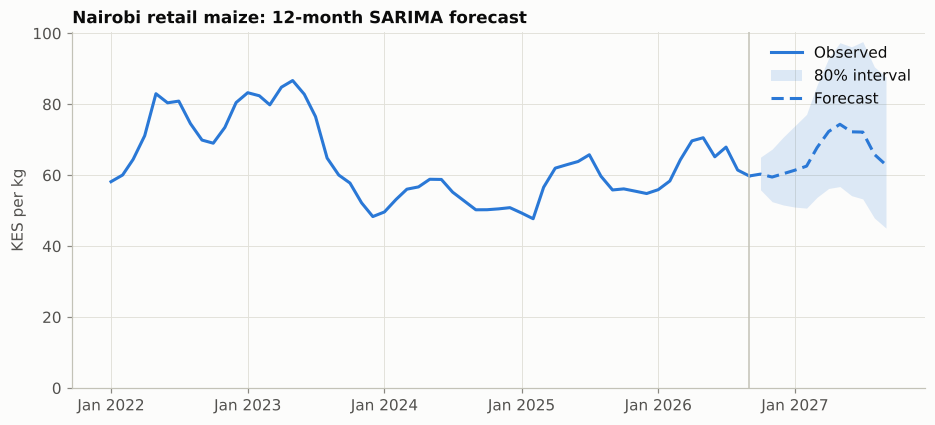

,forecast_kes,low_80,high_80
Oct 2026,60.3,55.9,65.1
Nov 2026,59.5,52.5,67.3
Dec 2026,60.4,51.6,70.8
Jan 2027,61.4,51.0,73.9
Feb 2027,62.5,50.7,77.1
Mar 2027,67.8,53.8,85.4
Apr 2027,72.3,56.2,92.9
May 2027,74.3,56.8,97.3
Jun 2027,72.2,54.2,96.2
Jul 2027,72.1,53.3,97.6


In [16]:
res = fit(y)
fc = res.get_forecast(12)
mean = np.exp(fc.predicted_mean)
line = pd.concat([s.iloc[-1:], mean])   # join forecast to last observation
ci = np.exp(fc.conf_int(alpha=0.2))   # 80% interval

fig, ax = plt.subplots(figsize=(10, 4.2))
hist = s["2022-01-01":]
ax.plot(hist.index, hist.values, color=BLUE, label="Observed")
ax.fill_between(ci.index, ci.iloc[:, 0], ci.iloc[:, 1], color=BLUE, alpha=0.15, lw=0, label="80% interval")
ax.plot(line.index, line.values, color=BLUE, ls=(0, (4, 2)), label="Forecast")
ax.axvline(s.index[-1], color=AXIS, lw=1)
ax.set_ylabel("KES per kg"); ax.set_ylim(bottom=0)
ax.legend(loc="upper right")
ax.set_title("Nairobi retail maize: 12-month SARIMA forecast")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
fig.savefig(FIG / "07_maize_forecast_nairobi.png")
plt.show()

forecast = pd.DataFrame({"forecast_kes": mean.round(1), "low_80": ci.iloc[:, 0].round(1), "high_80": ci.iloc[:, 1].round(1)})
forecast.rename_axis("month").to_csv(ROOT / "reports" / "forecast_maize_nairobi.csv")
forecast.index = forecast.index.strftime("%b %Y")
forecast

The model expects the usual seasonal pattern: prices ease into the Oct–Dec harvest window, then climb towards a lean-season
high in May–June 2027. The 80% interval is wide: by May 2027 it runs from about KES 57 to KES 97 around a central forecast of KES 74. A failed rainy season would push prices above it, as
in 2022, because a model trained on prices alone cannot anticipate a drought. A production version should add rainfall or vegetation (NDVI)
forecasts as external regressors.

## 9. Key findings

1. **Drought is the dominant driver.** National average retail maize nearly doubled (+93%), from KES 51/kg in 2019–20 to a 3-month peak of KES 99/kg in 2023. Sorghum rose 82% and beans 76%. Every staple rose together.
2. **The arid north was hit hardest.** ASAL markets saw maize rise about 125% from baseline to peak, against roughly 80% in high-potential markets. Mandera peaked at more than double its pre-drought price.
3. **Location costs money every year.** ASAL households pay a 25–40% premium in normal years, and 45–65% in the 2022–23 drought.
4. **Seasonality is predictable and large.** On average maize is about 25% dearer in May than in November. Timing purchases is a low-cost saving.
5. **Potatoes are the most volatile staple** (about 15% monthly swings, double maize). Milk and pulses are the most stable.
6. **Currency matters for dollar budgets.** KES depreciation in 2023 meant dollar-denominated food costs fell sharply while shilling prices stayed high.
7. **Retailers passed costs through.** They did not widen margins: the mark-up over wholesale stayed close to 25%.

*Data are simulated; see README for how to run on the real WFP/HDX file.*

In [17]:
con.close()